In [11]:
import pandas as pd
import numpy as np

# Load the uploaded files
X = pd.read_csv('X_features.csv')
y = pd.read_csv('y_target.csv').squeeze()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nFirst 5 rows of X:")
display(X.head())

print("\nFirst 5 values of y:")
display(y.head())

X shape: (1424, 17)
y shape: (1424,)

X columns:
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'number_of_monitoring_stations', 'Year', 'Is_Lohri_Month', 'Is_Diwali_Season', 'Is_Paddy_Harvesting']

First 5 rows of X:


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,number_of_monitoring_stations,Year,Is_Lohri_Month,Is_Diwali_Season,Is_Paddy_Harvesting
0,63.220000,135.760000,46.810000,15.960000,45.210000,24.730000,1.110000,7.79,8.10,9.1400,0.3800,0.780000,3.0,2020,1,0,0
1,57.483333,118.843333,32.276667,15.643333,31.983333,42.996667,1.013333,7.85,9.48,8.4400,0.3800,0.803333,2.0,2023,1,0,0
2,51.746667,101.926667,17.743333,15.326667,18.756667,61.263333,0.916667,7.91,10.86,7.7400,0.3800,0.826667,3.0,2024,1,0,0
3,46.010000,85.010000,3.210000,15.010000,5.530000,79.530000,0.820000,7.97,12.24,7.0400,0.3800,0.850000,3.0,2020,0,0,0
4,38.725000,77.147500,9.092500,16.092500,12.092500,72.545000,0.790000,8.32,11.74,6.6375,0.3175,0.965000,3.0,2023,0,0,0



First 5 values of y:


,AQI
0,132
1,306
2,239
3,95
4,110


In [12]:
print("Missing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Missing values in X:
PM2.5                            0
PM10                             0
NO                               0
NO2                              0
NOx                              0
NH3                              0
CO                               0
SO2                              0
O3                               0
Benzene                          0
Toluene                          0
Xylene                           0
number_of_monitoring_stations    0
Year                             0
Is_Lohri_Month                   0
Is_Diwali_Season                 0
Is_Paddy_Harvesting              0
dtype: int64

Missing values in y:
0


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1139
Testing samples: 285


In [14]:
# Model 1 — Linear Regression
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [15]:
# Model 2 — Random Forest
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [17]:
#Calculate MAE, RMSE and R²
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Linear Regression metrics
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

# Random Forest metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

In [18]:
print("========== REGRESSION RESULTS ==========\n")

print("Linear Regression")
print("-------------------------")
print("MAE  :", round(linear_mae, 2))
print("RMSE :", round(linear_rmse, 2))
print("R²   :", round(linear_r2, 3))

print("\nRandom Forest Regression")
print("-------------------------")
print("MAE  :", round(rf_mae, 2))
print("RMSE :", round(rf_rmse, 2))
print("R²   :", round(rf_r2, 3))

========== REGRESSION RESULTS ==========

Linear Regression
-------------------------
MAE  : 42.2
RMSE : 53.74
R²   : 0.455

Random Forest Regression
-------------------------
MAE  : 30.61
RMSE : 41.67
R²   : 0.672


In [19]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        linear_mae,
        rf_mae
    ],
    'RMSE': [
        linear_rmse,
        rf_rmse
    ],
    'R²': [
        linear_r2,
        rf_r2
    ]
})

results = results.round(3)

display(results)

,Model,MAE,RMSE,R²
0,Linear Regression,42.202,53.740,0.455
1,Random Forest,30.605,41.675,0.672


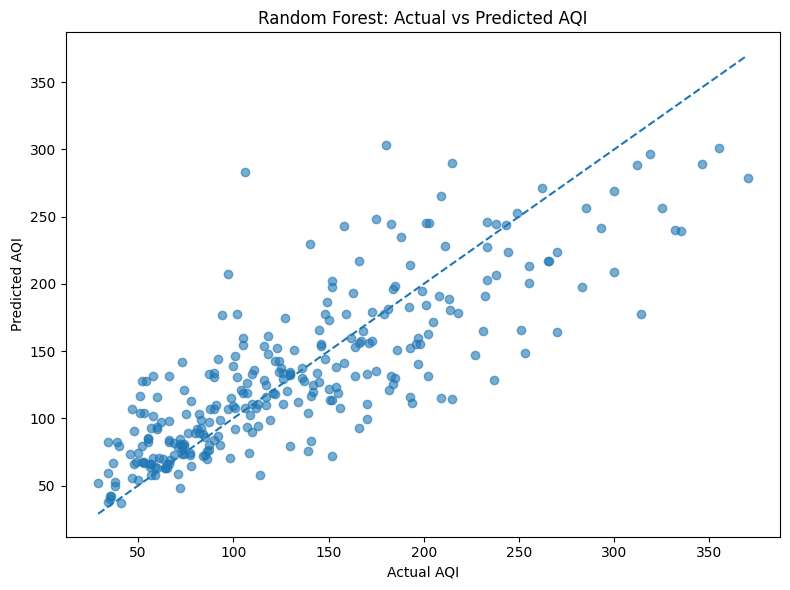

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.6)

minimum = min(y_test.min(), rf_pred.min())
maximum = max(y_test.max(), rf_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Random Forest: Actual vs Predicted AQI")

plt.tight_layout()
plt.show()